In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DATA_FILE = "Ch7-Ch8_HandsOn_Dummy_Datasets.xlsx"  # Change .csv to .xlsx

ch7 = pd.read_excel(
    DATA_FILE,
    sheet_name="Ch7_Worked_Data"
)

print(ch7.head())
print("\nRows and columns:", ch7.shape)
print("\nColumn names:")
print(ch7.columns.tolist())

  Student_ID     Programme  Study_Hours  Quiz_Score  Attendance_Rate  \
0        S01  Data Science          2.0          55               68   
1        S02  Data Science          3.0          60               72   
2        S03  Data Science          4.0          66               78   
3        S04  Data Science          5.0          72               82   
4        S05  Data Science          6.0          78               88   

   Satisfaction_Rating  
0                    2  
1                    3  
2                    3  
3                    4  
4                    4  

Rows and columns: (20, 6)

Column names:
['Student_ID', 'Programme', 'Study_Hours', 'Quiz_Score', 'Attendance_Rate', 'Satisfaction_Rating']


In [9]:
quiz = ch7["Quiz_Score"].dropna() 
q1 = quiz.quantile(0.25) 
q3 = quiz.quantile(0.75) 
iqr = q3 - q1 

print("Mean:", round(quiz.mean(), 2)) 
print("Median:", round(quiz.median(), 2)) 
print("Minimum:", quiz.min()) 
print("Maximum:", quiz.max()) 
print("Standard deviation:", round(quiz.std(), 2)) 
print("Q1:", q1) 
print("Q3:", q3) 
print("IQR:", iqr)

Mean: 69.0
Median: 69.5
Minimum: 35
Maximum: 91
Standard deviation: 13.65
Q1: 59.75
Q3: 78.75
IQR: 19.0


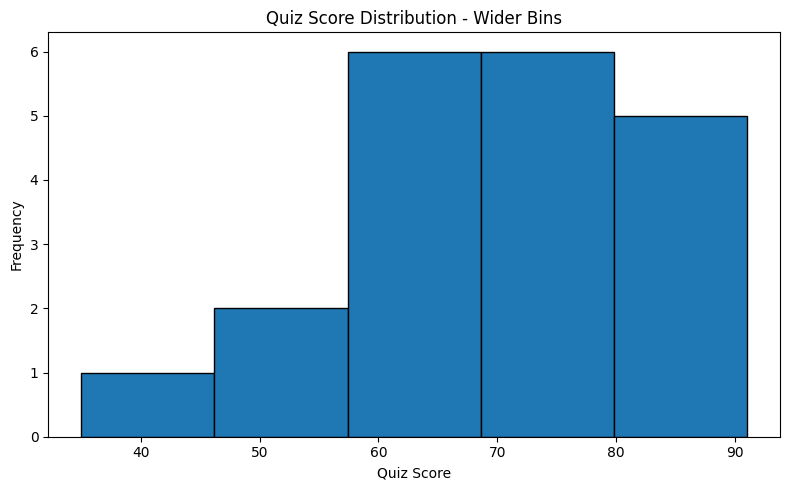

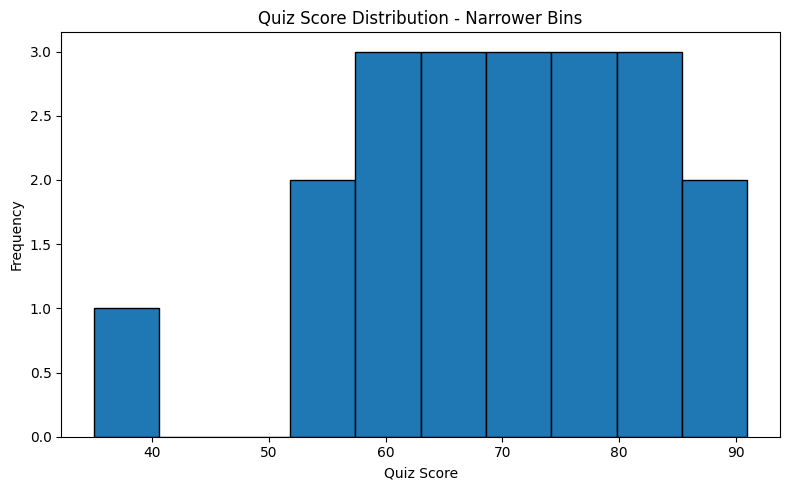

In [10]:
# Histogram with about 5 wider bins 
fig, ax = plt.subplots(figsize=(8, 5)) 
 
ax.hist( 
    ch7["Quiz_Score"].dropna(), 
    bins=5, 
    edgecolor="black" 
) 
 
ax.set_title("Quiz Score Distribution - Wider Bins") 
ax.set_xlabel("Quiz Score") 
ax.set_ylabel("Frequency") 
 
plt.tight_layout() 
plt.show() 
# Histogram with 10 narrower bins 
fig, ax = plt.subplots(figsize=(8, 5)) 
 
ax.hist( 
    ch7["Quiz_Score"].dropna(), 
    bins=10, 
    edgecolor="black" 
) 
 
ax.set_title("Quiz Score Distribution - Narrower Bins") 
ax.set_xlabel("Quiz Score") 
ax.set_ylabel("Frequency") 
 
plt.tight_layout() 
plt.show()

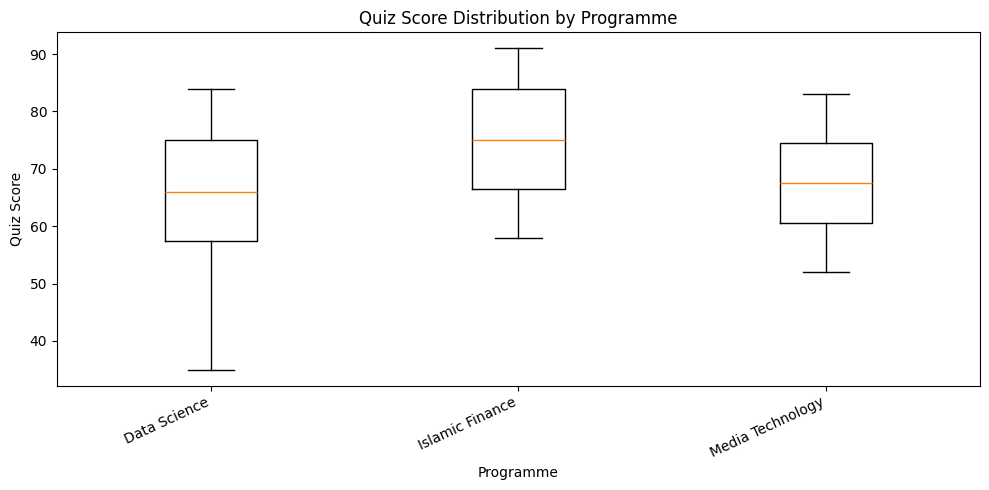

In [11]:
programmes = sorted(ch7["Programme"].unique()) 
 
box_data = [ 
    ch7.loc[ 
        ch7["Programme"] == programme, 
        "Quiz_Score" 
    ].dropna().values 
    for programme in programmes 
] 
 
fig, ax = plt.subplots(figsize=(10, 5)) 
 
ax.boxplot(box_data) 
ax.set_xticks(range(1, len(programmes) + 1)) 
ax.set_xticklabels(programmes, rotation=25, ha="right") 
 
ax.set_title("Quiz Score Distribution by Programme") 
ax.set_xlabel("Programme") 
ax.set_ylabel("Quiz Score") 
 
plt.tight_layout() 
plt.show()

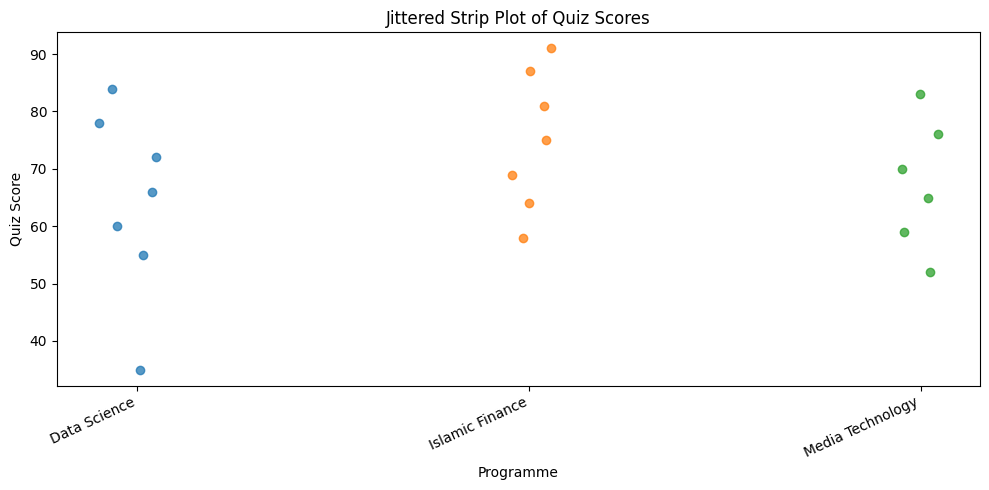

In [12]:
rng = np.random.default_rng(42) 
 
fig, ax = plt.subplots(figsize=(10, 5)) 
 
for position, programme in enumerate(programmes, start=1): 
    values = ch7.loc[ 
        ch7["Programme"] == programme, 
        "Quiz_Score" 
    ].dropna().values 
 
    jitter = rng.normal( 
        loc=0, 
        scale=0.05, 
        size=len(values) 
    ) 
 
    x_values = position + jitter 
 
    ax.scatter( 
        x_values, 
        values, 
        alpha=0.75 
    ) 
 
ax.set_xticks(range(1, len(programmes) + 1)) 
ax.set_xticklabels(programmes, rotation=25, ha="right") 
 
ax.set_title("Jittered Strip Plot of Quiz Scores") 
ax.set_xlabel("Programme") 
ax.set_ylabel("Quiz Score") 
 
plt.tight_layout() 
plt.show()

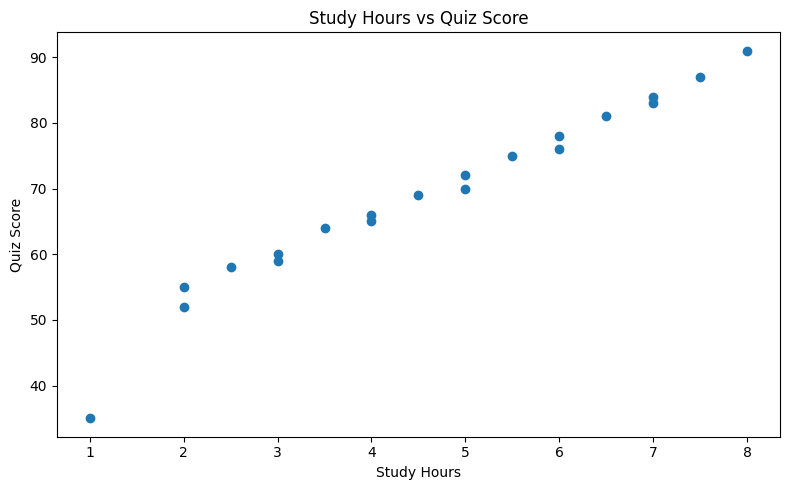

In [13]:
fig, ax = plt.subplots(figsize=(8, 5)) 
 
ax.scatter( 
    ch7["Study_Hours"], 
    ch7["Quiz_Score"] 
) 
 
ax.set_title("Study Hours vs Quiz Score") 
ax.set_xlabel("Study Hours") 
ax.set_ylabel("Quiz Score") 
 
plt.tight_layout() 
plt.show()

In [14]:
correlation = ch7[ 
    "Study_Hours" 
].corr( 
    ch7["Quiz_Score"] 
) 
 
print( 
    "Pearson correlation:", 
    round(correlation, 3) 
) 

Pearson correlation: 0.979


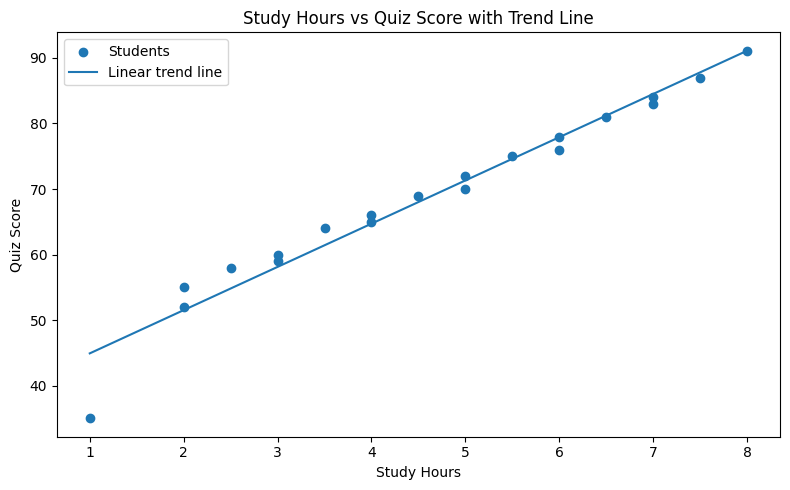

Slope: 6.6
Intercept: 38.32


In [16]:
x = ch7["Study_Hours"].to_numpy() 
y = ch7["Quiz_Score"].to_numpy() 
 
slope, intercept = np.polyfit(x, y, 1) 
 
x_line = np.linspace( 
    x.min(), 
    x.max(), 
    100 
) 
 
y_line = slope * x_line + intercept 
 
fig, ax = plt.subplots(figsize=(8, 5)) 
 
ax.scatter(x, y, label="Students") 
ax.plot( 
    x_line, 
    y_line, 
    label="Linear trend line" 
)

ax.set_title("Study Hours vs Quiz Score with Trend Line") 
ax.set_xlabel("Study Hours") 
ax.set_ylabel("Quiz Score") 
ax.legend() 
 
plt.tight_layout() 
plt.show() 
 
print("Slope:", round(slope, 2)) 
print("Intercept:", round(intercept, 2))

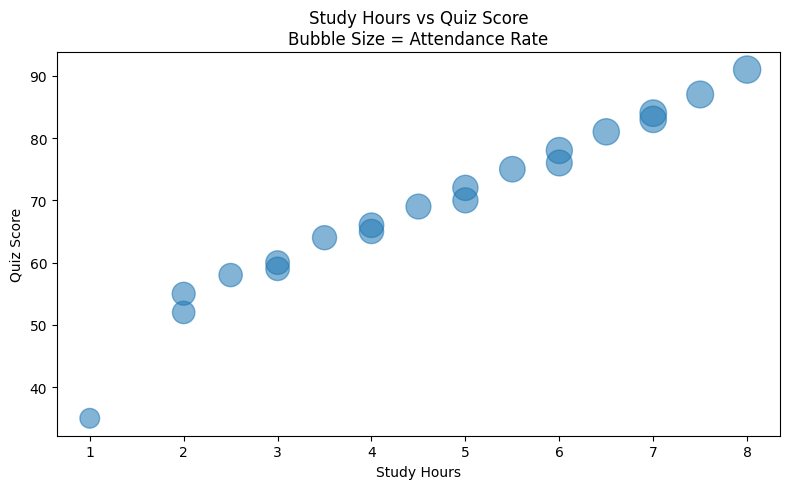

In [17]:
bubble_size = ch7["Attendance_Rate"] * 4 
 
fig, ax = plt.subplots(figsize=(8, 5)) 
 
ax.scatter( 
    ch7["Study_Hours"], 
    ch7["Quiz_Score"], 
    s=bubble_size, 
    alpha=0.55 
) 
 
ax.set_title( 
    "Study Hours vs Quiz Score\nBubble Size = Attendance Rate" 
) 
ax.set_xlabel("Study Hours") 
ax.set_ylabel("Quiz Score") 
 
plt.tight_layout() 
plt.show()

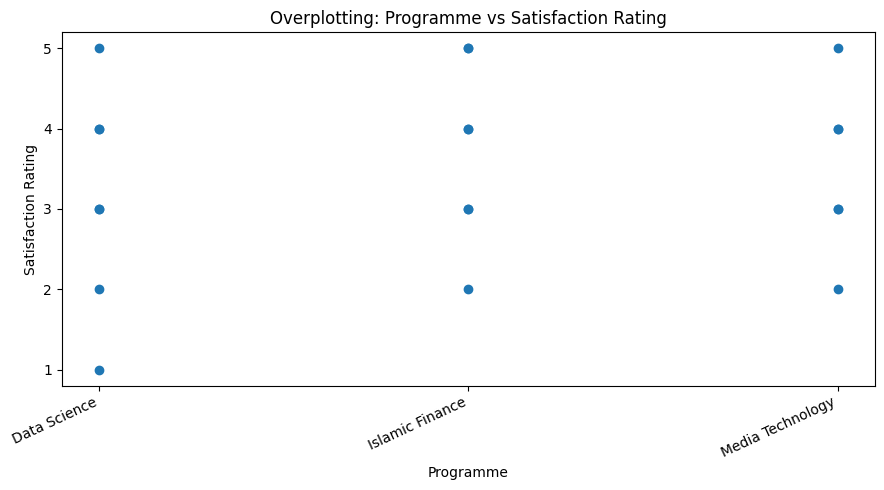

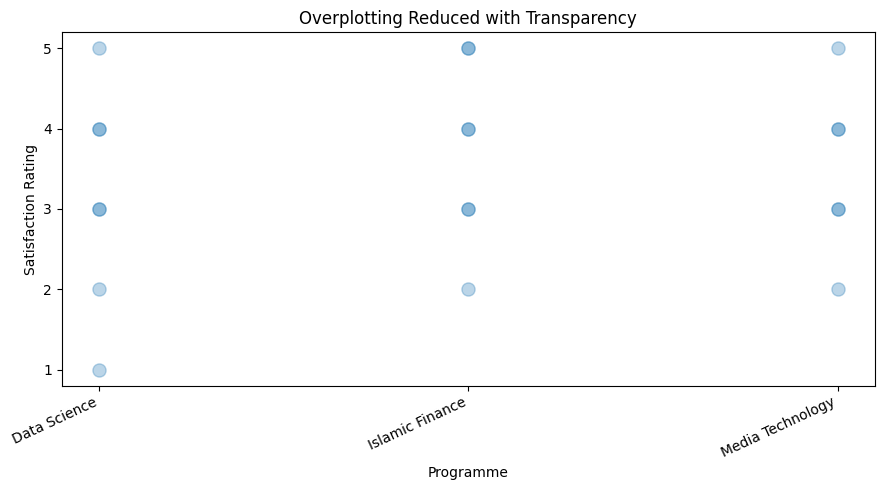

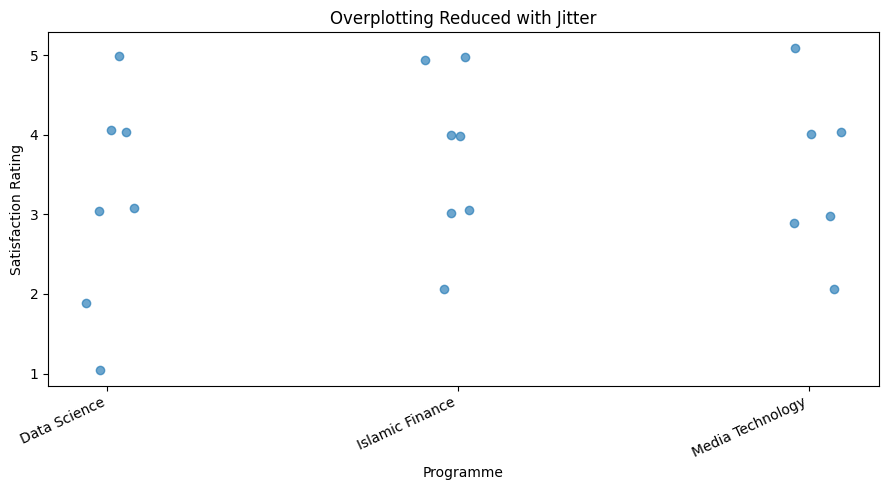

In [18]:
# 9A. Overplotting without transparency or jitter 
 
programme_codes = { 
    programme: i + 1 
    for i, programme in enumerate(programmes) 
} 
 
x_plain = ch7["Programme"].map(programme_codes) 
 
fig, ax = plt.subplots(figsize=(9, 5)) 
 
ax.scatter( 
    x_plain, 
    ch7["Satisfaction_Rating"] 
 
) 
 
ax.set_xticks(range(1, len(programmes) + 1)) 
ax.set_xticklabels(programmes, rotation=25, ha="right") 
ax.set_yticks([1, 2, 3, 4, 5]) 
 
ax.set_title("Overplotting: Programme vs Satisfaction Rating") 
ax.set_xlabel("Programme") 
ax.set_ylabel("Satisfaction Rating") 
 
plt.tight_layout() 
plt.show() 

# 9B. Reduce overplotting with transparency 
 
fig, ax = plt.subplots(figsize=(9, 5)) 
 
ax.scatter( 
    x_plain, 
    ch7["Satisfaction_Rating"], 
    alpha=0.30, 
    s=90 
) 
 
ax.set_xticks(range(1, len(programmes) + 1)) 
ax.set_xticklabels(programmes, rotation=25, ha="right") 
ax.set_yticks([1, 2, 3, 4, 5]) 
 
ax.set_title("Overplotting Reduced with Transparency") 
ax.set_xlabel("Programme") 
ax.set_ylabel("Satisfaction Rating") 
 
plt.tight_layout() 
plt.show() 

# 9C. Reduce overplotting with jitter 
 
rng = np.random.default_rng(123) 
 
x_jitter = ( 
    x_plain.to_numpy() 
    + rng.normal(0, 0.06, len(ch7)) 
) 
 
y_jitter = ( 
    ch7["Satisfaction_Rating"].to_numpy() 
    + rng.normal(0, 0.05, len(ch7)) 
) 
 
fig, ax = plt.subplots(figsize=(9, 5)) 
 
ax.scatter( 
    x_jitter, 
    y_jitter, 
    alpha=0.65 
) 
 
ax.set_xticks(range(1, len(programmes) + 1)) 
ax.set_xticklabels(programmes, rotation=25, ha="right") 
ax.set_yticks([1, 2, 3, 4, 5]) 
 
ax.set_title("Overplotting Reduced with Jitter") 
ax.set_xlabel("Programme") 
ax.set_ylabel("Satisfaction Rating") 
plt.tight_layout() 
plt.show() 

In [23]:
quiz = ch7["Quiz_Score"].dropna()
q1 = quiz.quantile(0.25)
q3 = quiz.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Use .loc with parentheses for each condition and the bitwise OR operator (|)
potential_outliers = ch7.loc[
    (ch7["Quiz_Score"] < lower_bound) | (ch7["Quiz_Score"] > upper_bound),
    ["Student_ID", "Programme", "Quiz_Score"]
]

print("Lower IQR boundary:", lower_bound)
print("Upper IQR boundary:", upper_bound)
print("\nPotential outliers:")
print(potential_outliers)

Lower IQR boundary: 31.25
Upper IQR boundary: 107.25

Potential outliers:
Empty DataFrame
Columns: [Student_ID, Programme, Quiz_Score]
Index: []


In [24]:
monthly = pd.read_excel( 
DATA_FILE, 
sheet_name="Ch8_Worked_Monthly" 
) 
daily = pd.read_excel( 
DATA_FILE, 
sheet_name="Ch8_Worked_Daily" 
) 
# Ensure that the date columns are true datetime values. 
monthly["Date"] = pd.to_datetime(monthly["Date"]) 
daily["Date"] = pd.to_datetime(daily["Date"]) 
# Always sort time-series data chronologically before plotting. 
monthly = monthly.sort_values("Date") 
daily = daily.sort_values("Date") 
print(monthly.head()) 
print() 
print(daily.head())

        Date  Programme_A_Activity  Programme_B_Activity  Total_Activity  \
0 2026-01-01                   120                 110.0           230.0   
1 2026-02-01                   128                 115.0           243.0   
2 2026-03-01                   135                 121.0           256.0   
3 2026-04-01                   142                 129.0           271.0   
4 2026-05-01                   150                 137.0           287.0   

   Support_Requests      Annotation  
0                18  Semester Start  
1                17             NaN  
2                16             NaN  
3                15             NaN  
4                15             NaN  

        Date  Daily_LMS_Logins
0 2026-03-01                60
1 2026-03-02                85
2 2026-03-03                90
3 2026-03-04                95
4 2026-03-05               100


In [25]:
print("Monthly Date type:", monthly["Date"].dtype) 
print("Daily Date type:", daily["Date"].dtype) 
print("\nMonthly date range:") 
print("Start:", monthly["Date"].min()) 
print("End:", monthly["Date"].max()) 
monthly_intervals = monthly["Date"].diff() 
print("\nIntervals between monthly observations:") 
print(monthly_intervals)

Monthly Date type: datetime64[us]
Daily Date type: datetime64[us]

Monthly date range:
Start: 2026-01-01 00:00:00
End: 2026-12-01 00:00:00

Intervals between monthly observations:
0        NaT
1    31 days
2    28 days
3    31 days
4    30 days
5    31 days
6    30 days
7    31 days
8    31 days
9    30 days
10   31 days
11   30 days
Name: Date, dtype: timedelta64[us]


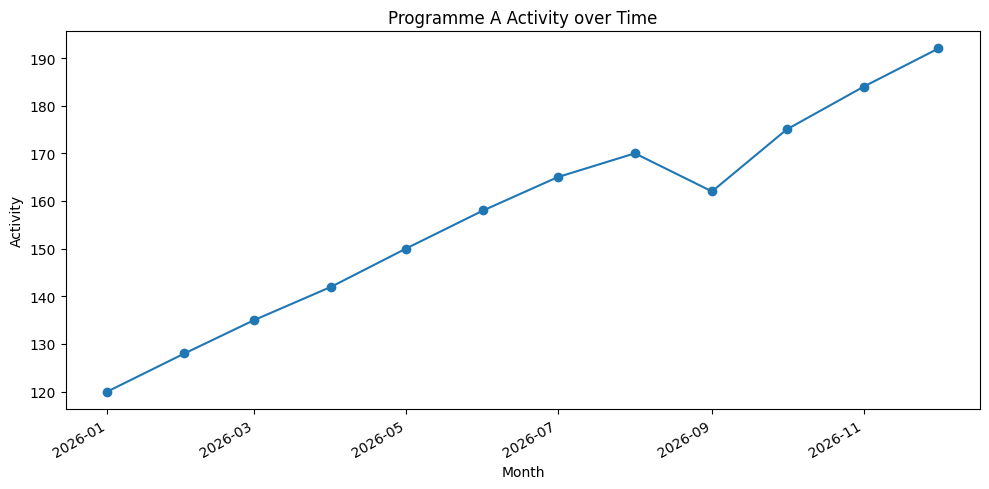

In [26]:
fig, ax = plt.subplots(figsize=(10, 5)) 
ax.plot( 
monthly["Date"], 
monthly["Programme_A_Activity"], 
marker="o" 
) 
 
ax.set_title("Programme A Activity over Time") 
ax.set_xlabel("Month") 
ax.set_ylabel("Activity") 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show()

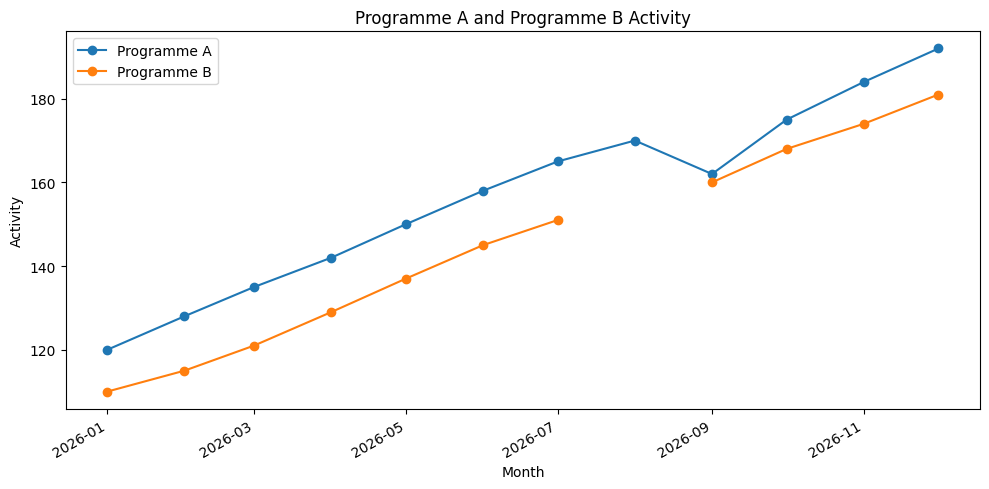

In [27]:
fig, ax = plt.subplots(figsize=(10, 5)) 
 
ax.plot( 
    monthly["Date"], 
    monthly["Programme_A_Activity"], 
    marker="o", 
    label="Programme A" 
) 
 
ax.plot( 
    monthly["Date"], 
    monthly["Programme_B_Activity"], 
    marker="o", 
    label="Programme B" 
) 
 
ax.set_title("Programme A and Programme B Activity") 
ax.set_xlabel("Month") 
ax.set_ylabel("Activity") 
ax.legend() 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show()

Missing Programme B observations:
        Date  Programme_B_Activity     Annotation
7 2026-08-01                   NaN  Missing Point


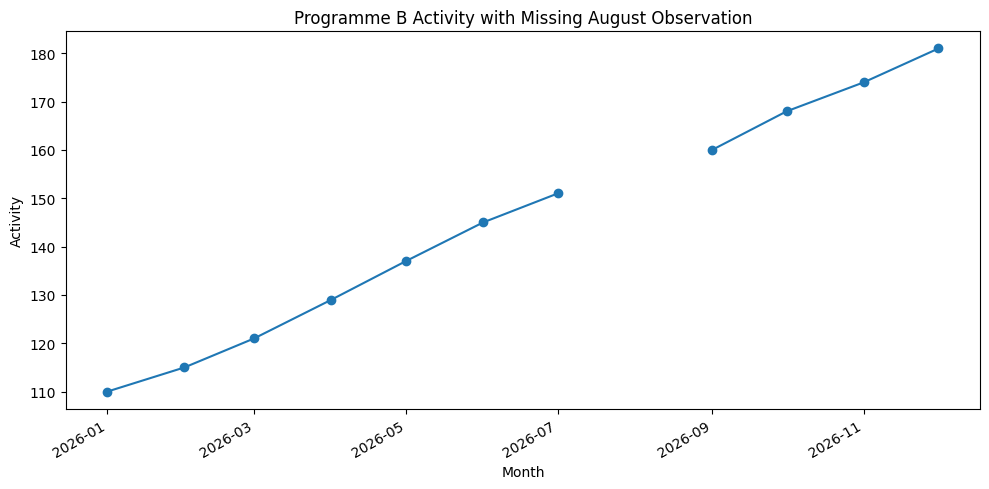

In [29]:
missing_rows = monthly[ 
    monthly["Programme_B_Activity"].isna() 
] 
 
print("Missing Programme B observations:") 
print( 
    missing_rows[ 
        ["Date", "Programme_B_Activity", "Annotation"] 
    ] 
) 
 
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot( 
    monthly["Date"], 
    monthly["Programme_B_Activity"], 
    marker="o" 
) 
 
ax.set_title("Programme B Activity with Missing August Observation") 
ax.set_xlabel("Month") 
ax.set_ylabel("Activity") 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show()

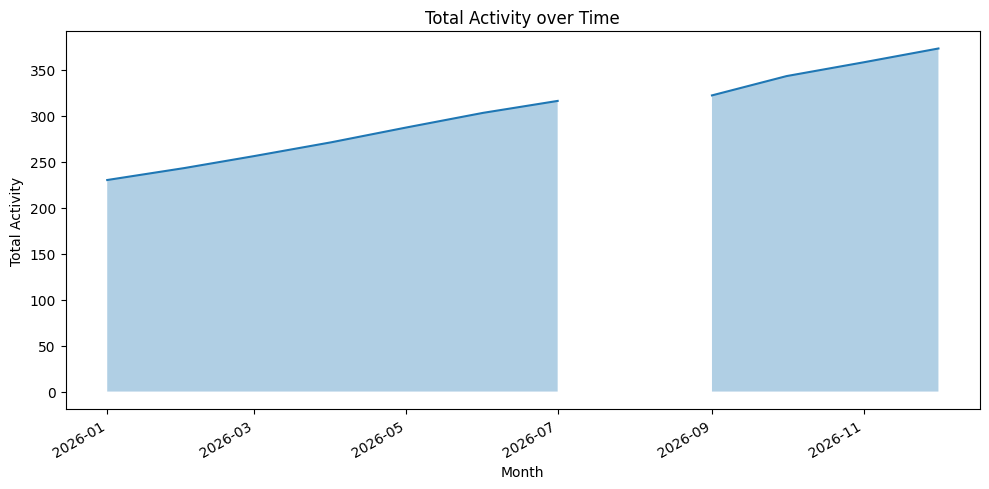

In [30]:
fig, ax = plt.subplots(figsize=(10, 5)) 
 
ax.fill_between( 
    monthly["Date"], 
    monthly["Total_Activity"], 
    alpha=0.35 
) 
 
ax.plot( 
    monthly["Date"], 
    monthly["Total_Activity"] 
) 
 
ax.set_title("Total Activity over Time") 
ax.set_xlabel("Month") 
ax.set_ylabel("Total Activity") 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show()

         Date  Programme_A_Activity  A_3_Month_MA
0  2026-01-01                   120           NaN
1  2026-02-01                   128           NaN
2  2026-03-01                   135    127.666667
3  2026-04-01                   142    135.000000
4  2026-05-01                   150    142.333333
5  2026-06-01                   158    150.000000
6  2026-07-01                   165    157.666667
7  2026-08-01                   170    164.333333
8  2026-09-01                   162    165.666667
9  2026-10-01                   175    169.000000
10 2026-11-01                   184    173.666667
11 2026-12-01                   192    183.666667


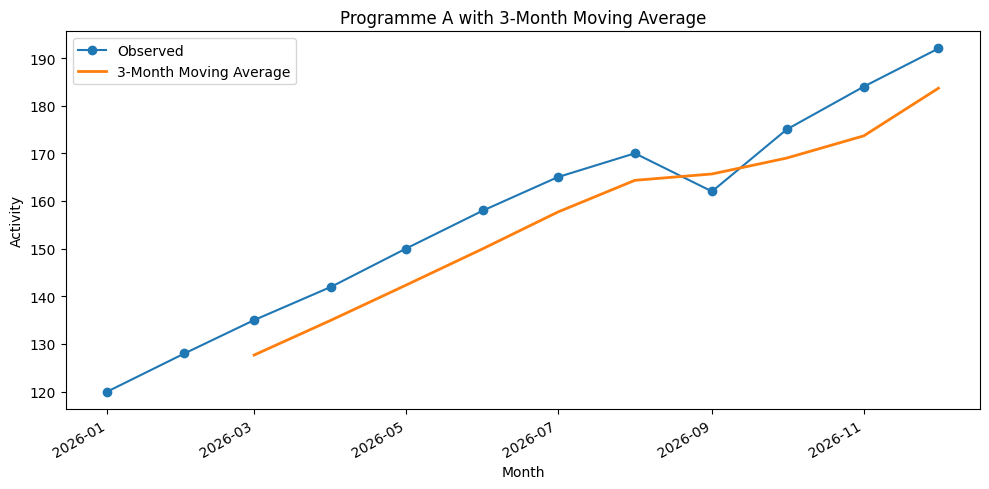

In [31]:
monthly["A_3_Month_MA"] = ( 
    monthly["Programme_A_Activity"] 
    .rolling(window=3) 
    .mean() 
) 
 
print( 
    monthly[ 
        ["Date", "Programme_A_Activity", "A_3_Month_MA"] 
    ] 
) 

fig, ax = plt.subplots(figsize=(10, 5)) 
 
ax.plot( 
    monthly["Date"], 
    monthly["Programme_A_Activity"], 
    marker="o", 
    label="Observed" 
) 
 
ax.plot( 
    monthly["Date"], 
    monthly["A_3_Month_MA"], 
    linewidth=2, 
    label="3-Month Moving Average" 
) 
 
ax.set_title("Programme A with 3-Month Moving Average") 
ax.set_xlabel("Month") 
ax.set_ylabel("Activity") 
ax.legend() 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show()

         Date  Programme_A_Activity  A_Index_100
0  2026-01-01                   120   100.000000
1  2026-02-01                   128   106.666667
2  2026-03-01                   135   112.500000
3  2026-04-01                   142   118.333333
4  2026-05-01                   150   125.000000
5  2026-06-01                   158   131.666667
6  2026-07-01                   165   137.500000
7  2026-08-01                   170   141.666667
8  2026-09-01                   162   135.000000
9  2026-10-01                   175   145.833333
10 2026-11-01                   184   153.333333
11 2026-12-01                   192   160.000000


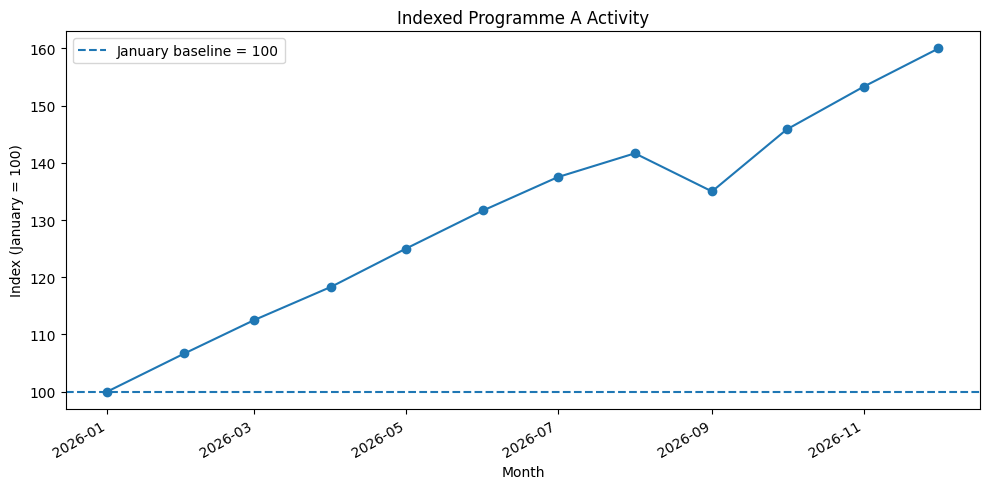

In [32]:
baseline = monthly.loc[ 
    monthly["Date"] == monthly["Date"].min(), 
    "Programme_A_Activity" 
].iloc[0] 
 
monthly["A_Index_100"] = ( 
    monthly["Programme_A_Activity"] 
    / baseline 
    * 100 
) 
 
print( 
    monthly[ 
        ["Date", "Programme_A_Activity", "A_Index_100"] 
    ] 
) 
 
fig, ax = plt.subplots(figsize=(10, 5)) 
 
ax.plot( 
    monthly["Date"], 
    monthly["A_Index_100"], 
    marker="o" 
) 
 
ax.axhline( 
    100, 
    linestyle="--", 

 label="January baseline = 100" 
) 
 
ax.set_title("Indexed Programme A Activity") 
ax.set_xlabel("Month") 
ax.set_ylabel("Index (January = 100)") 
ax.legend() 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show() 

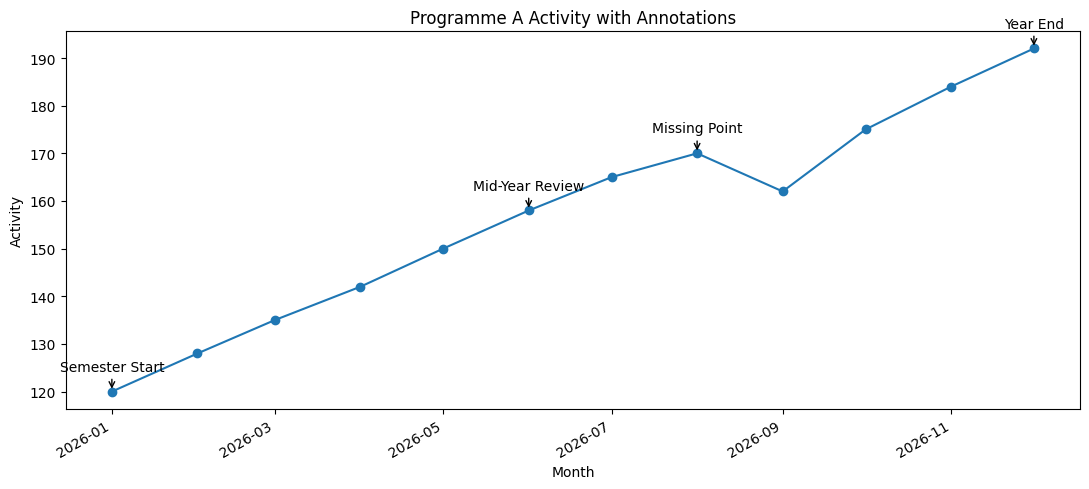

In [33]:
fig, ax = plt.subplots(figsize=(11, 5)) 
 
ax.plot( 
    monthly["Date"], 
    monthly["Programme_A_Activity"], 
    marker="o" 
) 
 
for _, row in monthly.iterrows(): 
    annotation = row["Annotation"] 
 
    if pd.notna(annotation): 
        ax.annotate( 
            annotation, 
            xy=( 
                row["Date"], 
                row["Programme_A_Activity"] 
            ), 
            xytext=(0, 15), 
            textcoords="offset points", 
            ha="center", 
            arrowprops={ 
                "arrowstyle": "->" 
            } 
        ) 
 
ax.set_title("Programme A Activity with Annotations") 
ax.set_xlabel("Month") 
ax.set_ylabel("Activity") 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show()

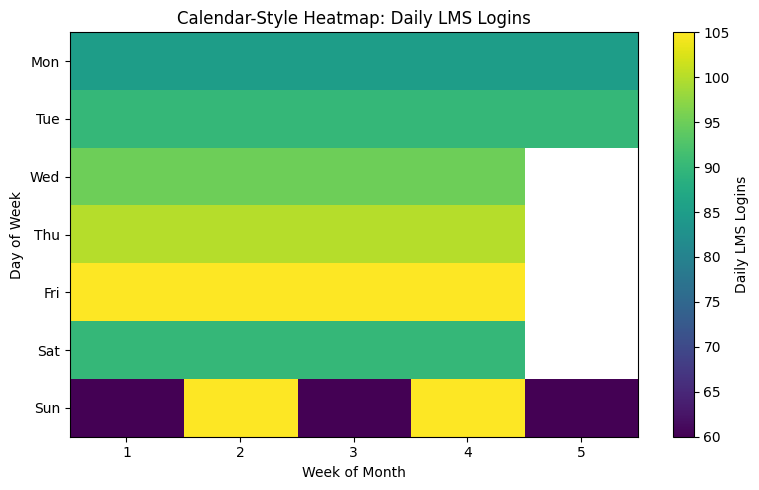

In [34]:
daily["Day_of_Week"] = daily["Date"].dt.dayofweek 
daily["Week_of_Month"] = ( 
    (daily["Date"].dt.day - 1) // 7 
    + 1 
) 
 
heatmap_data = daily.pivot( 
    index="Day_of_Week", 
    columns="Week_of_Month", 
    values="Daily_LMS_Logins" 
).reindex(range(7)) 
 
day_labels = [ 
    "Mon", "Tue", "Wed", 
    "Thu", "Fri", "Sat", "Sun" 
] 
 
fig, ax = plt.subplots(figsize=(8, 5)) 
 
image = ax.imshow( 
    heatmap_data.values, 
    aspect="auto" 
) 
 
ax.set_title("Calendar-Style Heatmap: Daily LMS Logins") 
ax.set_xlabel("Week of Month") 
ax.set_ylabel("Day of Week") 
 
ax.set_yticks(range(7)) 
ax.set_yticklabels(day_labels) 
 
ax.set_xticks( 
    range(len(heatmap_data.columns)) 
) 
ax.set_xticklabels( 
    heatmap_data.columns 
) 
 
fig.colorbar( 
    image, 
    ax=ax, 
    label="Daily LMS Logins" 
) 
 
plt.tight_layout() 
plt.show() 

         Date  Programme_A_Activity  A_Monthly_Change
0  2026-01-01                   120               NaN
1  2026-02-01                   128               8.0
2  2026-03-01                   135               7.0
3  2026-04-01                   142               7.0
4  2026-05-01                   150               8.0
5  2026-06-01                   158               8.0
6  2026-07-01                   165               7.0
7  2026-08-01                   170               5.0
8  2026-09-01                   162              -8.0
9  2026-10-01                   175              13.0
10 2026-11-01                   184               9.0
11 2026-12-01                   192               8.0


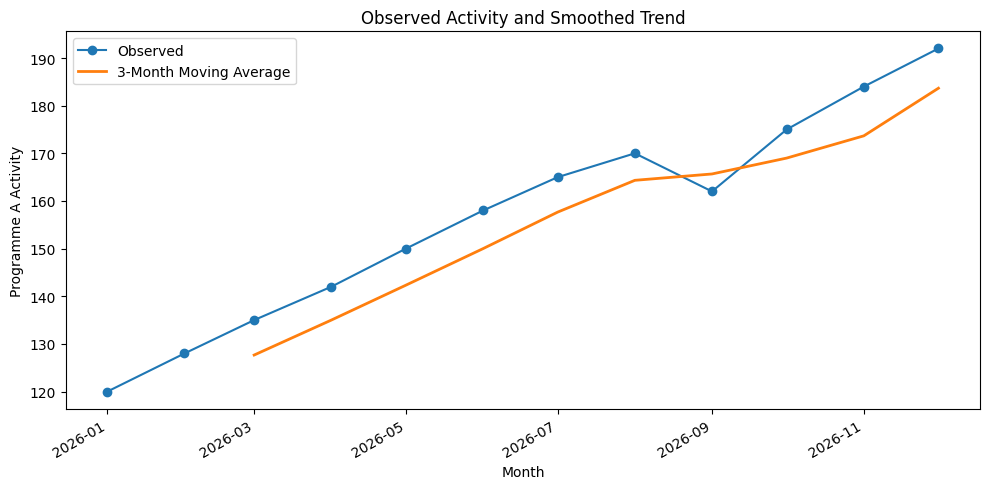

In [35]:
monthly["A_Monthly_Change"] = ( 
    monthly["Programme_A_Activity"] 
    .diff() 
) 
 
print(
    monthly[ 
        [ 
            "Date", 
            "Programme_A_Activity", 
            "A_Monthly_Change" 
        ] 
    ] 
) 
 
fig, ax = plt.subplots(figsize=(10, 5)) 
 
ax.plot( 
    monthly["Date"], 
    monthly["Programme_A_Activity"], 
    marker="o", 
    label="Observed" 
) 
 
ax.plot( 
    monthly["Date"], 
    monthly["A_3_Month_MA"], 
    linewidth=2, 
    label="3-Month Moving Average" 
) 
 
ax.set_title("Observed Activity and Smoothed Trend") 
ax.set_xlabel("Month") 
ax.set_ylabel("Programme A Activity") 
ax.legend() 
 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show()

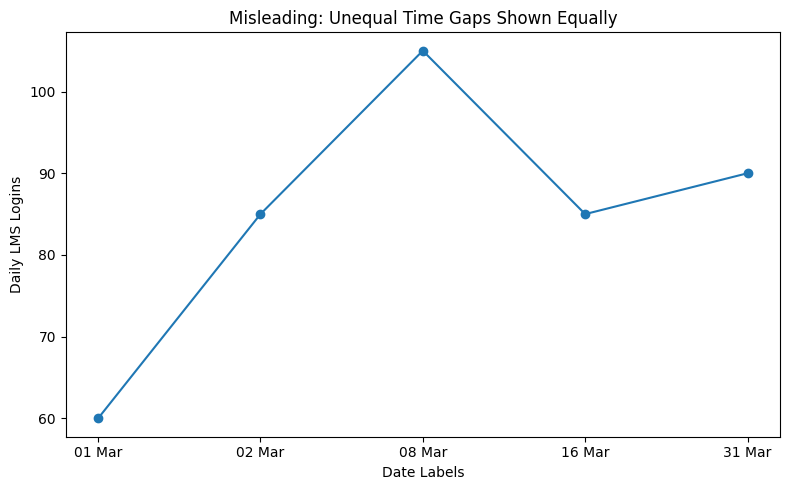

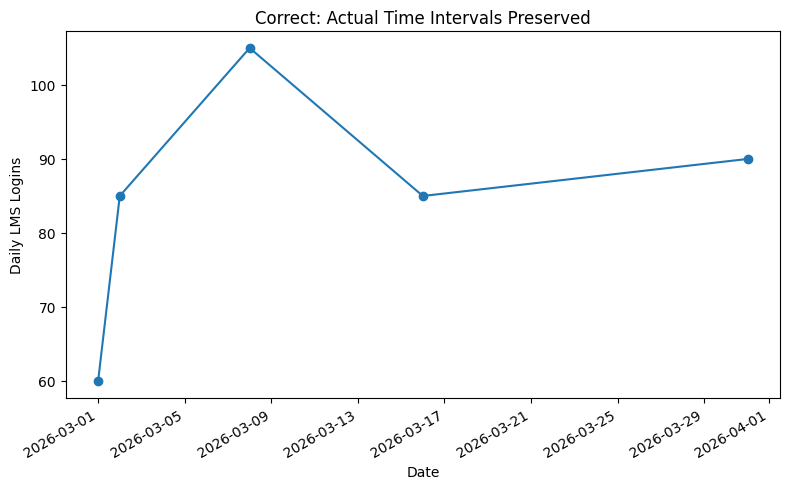

In [36]:
selected = daily.iloc[ 
    [0, 1, 7, 15, 30] 
].copy() 
 
# Misleading: unequal date gaps displayed as equal positions. 
equal_positions = np.arange(len(selected)) 
 
fig, ax = plt.subplots(figsize=(8, 5)) 
 
ax.plot( 
    equal_positions, 
    selected["Daily_LMS_Logins"], 
    marker="o" 
) 
 
ax.set_xticks(equal_positions) 
ax.set_xticklabels( 
    selected["Date"].dt.strftime("%d %b") 
)

ax.set_title("Misleading: Unequal Time Gaps Shown Equally") 
ax.set_xlabel("Date Labels") 
ax.set_ylabel("Daily LMS Logins") 
plt.tight_layout() 
plt.show() 
# Correct: use the actual datetime values on the x-axis. 
fig, ax = plt.subplots(figsize=(8, 5)) 
ax.plot( 
selected["Date"], 
selected["Daily_LMS_Logins"], 
marker="o" 
) 
ax.set_title("Correct: Actual Time Intervals Preserved") 
ax.set_xlabel("Date") 
ax.set_ylabel("Daily LMS Logins") 
fig.autofmt_xdate() 
plt.tight_layout() 
plt.show() 